# Supervised Machine Learning Algorithms
### Part A: Regression (Linear, Multiple Linear, Polynomial, Ridge, Lasso)
### Part B: Classification (KNN, Logistic Regression, Decision Tree, Random Forest, SVC)

## What is supervised learning?
In supervised learning we give the model **questions with answers**. The model learns the pattern from them, and then predicts the answer for new data.

- **X** = input features (area, age, blood test values ...)
- **y** = the answer / target (price, cancer yes or no ...)

There are two types, depending on what `y` is:

| Type | y is... | Example | Algorithms in this notebook |
|---|---|---|---|
| **Regression** | a **number** (continuous) | House price, salary, temperature | Linear, Multiple Linear, Polynomial, Ridge, Lasso |
| **Classification** | a **category / class** | Spam or not spam, cancer or no cancer | KNN, Logistic Regression, Decision Tree, Random Forest, SVC |

## Note about Ridge and Lasso
You listed Ridge and Lasso under classification, but they are actually **regression** algorithms (they are linear regression with a penalty). So I kept them in Part A. The classification part has Logistic Regression, which can also use the same L1/L2 penalty idea.

## Standard workflow (same for every model)
1. Get data, separate `X` and `y`
2. Split into train and test (`train_test_split`)
3. Scale the data if the model needs it
4. Create the model: `model = SomeModel()`
5. Train: `model.fit(X_train, y_train)`
6. Predict: `model.predict(X_test)`
7. Evaluate with metrics

Steps 4 to 6 are exactly the same syntax for all algorithms. Only the model name changes. That is the beauty of scikit-learn.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

---
# PART A: REGRESSION
Regression = predicting a **number**.

## Metrics for regression (we will use these everywhere)

| Metric | Meaning | Good value |
|---|---|---|
| **MAE** (Mean Absolute Error) | Average size of the error, in the same unit as y | Lower is better |
| **MSE** (Mean Squared Error) | Average of squared errors. Punishes big errors more | Lower is better |
| **RMSE** | Square root of MSE, back in the unit of y | Lower is better |
| **R2 score** | How much of the variation in y the model explains. 1 = perfect, 0 = same as predicting the average | Closer to 1 is better |

Syntax:
```python
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mean_absolute_error(y_test, y_pred)
mean_squared_error(y_test, y_pred)
r2_score(y_test, y_pred)
```

In [ ]:
# small helper so we do not write the same lines again and again
def reg_report(y_true, y_pred, name=""):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f"{name:<22} MAE = {mae:7.2f} | RMSE = {rmse:7.2f} | R2 = {r2:6.3f}")
    return {"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

## Dataset for regression: House prices (made with numpy)
Columns:
- **Area** in sq ft
- **Bedrooms**
- **Age** of the house in years
- **Price** in lakhs (this is our `y`)

The price is made from a formula plus random noise, so the data behaves like real data (not perfectly on a line).

In [ ]:
np.random.seed(42)
n = 200

house = pd.DataFrame({
    "Area":     np.random.randint(500, 3000, n),
    "Bedrooms": np.random.randint(1, 6, n),
    "Age":      np.random.randint(0, 30, n),
})
house["Price"] = (0.05 * house["Area"] + 4 * house["Bedrooms"]
                  - 0.8 * house["Age"] + 20 + np.random.normal(0, 10, n)).round(2)

house.head()

,Area,Bedrooms,Age,Price
0,1360,3,15,80.82
1,1794,2,20,99.57
2,1630,3,6,111.81
3,1595,3,3,124.10
4,2138,4,0,151.48


In [ ]:
house.describe().round(2)

,Area,Bedrooms,Age,Price
count,200.00,200.00,200.00,200.00
mean,1793.22,2.94,14.39,109.40
std,679.92,1.43,8.73,35.69
min,501.00,1.00,0.00,24.21
25%,1259.00,2.00,7.00,81.92
50%,1801.50,3.00,15.00,108.18
75%,2327.50,4.00,22.00,138.61
max,2989.00,5.00,29.00,201.51


---
# 1. Simple Linear Regression

### Definition
Simple Linear Regression finds the **best straight line** between **one input (X)** and the output (y).

Equation:

**y = m*x + c**

- `m` = slope (coefficient): how much y changes when x increases by 1
- `c` = intercept: the value of y when x = 0

The model chooses `m` and `c` so that the total distance between the line and all the points is as small as possible (this is called the **Least Squares** method).

Use it when: there is one feature and the relation looks like a straight line. Example: Area -> Price.

### Syntax
```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)          # X must be 2D: df[["Area"]]
y_pred = model.predict(X_test)

model.coef_        # slope (m)
model.intercept_   # intercept (c)
```

In [ ]:
# Simple linear regression: only Area to predict Price
X = house[["Area"]]          # double bracket = 2D
y = house["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.linear_model import LinearRegression

slr = LinearRegression()
slr.fit(X_train, y_train)

y_pred_slr = slr.predict(X_test)

print("Slope (m)     :", slr.coef_[0].round(4))
print("Intercept (c) :", round(slr.intercept_, 2))
print()
slr_result = reg_report(y_test, y_pred_slr, "Simple Linear")

Slope (m)     : 0.0481
Intercept (c) : 22.97

Simple Linear          MAE =   10.70 | RMSE =   13.19 | R2 =  0.835


How to read this: the slope is the price increase (in lakhs) for each extra sq ft. We also can predict for a new house:

In [ ]:
new_house = pd.DataFrame({"Area": [1500]})
print("Predicted price for 1500 sq ft:", slr.predict(new_house).round(2)[0], "lakhs")

# same thing by hand: y = m*x + c
print("By formula                    :", round(slr.coef_[0] * 1500 + slr.intercept_, 2))

Predicted price for 1500 sq ft: 95.04 lakhs
By formula                    : 95.04


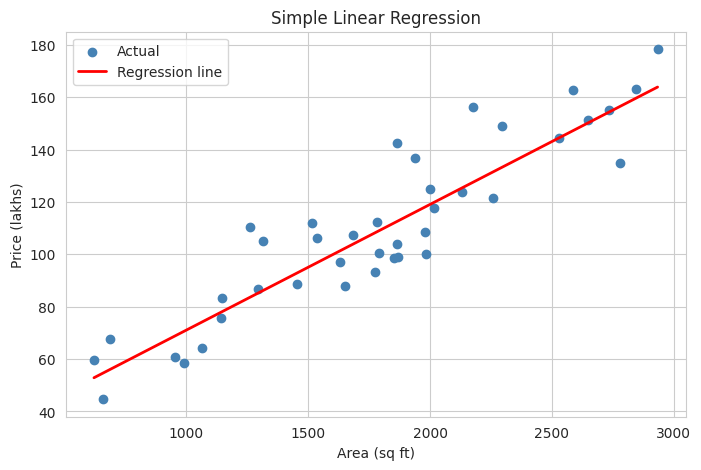

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color="steelblue", label="Actual")
plt.plot(X_test.sort_values("Area"), slr.predict(X_test.sort_values("Area")), color="red", linewidth=2, label="Regression line")
plt.xlabel("Area (sq ft)")
plt.ylabel("Price (lakhs)")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

The red line is the best straight line. The points are scattered around it because Bedrooms and Age (which we ignored) also affect the price. Can we do better by using them too? That is the next model.

### Advantages
- Very simple and easy to understand and explain.
- Very fast to train.
- Coefficients have clear meaning (price per sq ft).
- Good baseline model to start with.

### Disadvantages
- Only one feature, so it ignores everything else.
- Assumes the relation is a straight line.
- Sensitive to outliers (one extreme point can tilt the line).

---
# 2. Multiple Linear Regression

### Definition
Same idea as simple linear regression, but with **two or more input features**.

Equation:

**y = b0 + b1*x1 + b2*x2 + b3*x3 + ...**

Each feature gets its own coefficient. Now we are fitting a **plane** (or hyperplane) instead of a line.

In scikit-learn the class is the same `LinearRegression`. The only difference is that X has more than one column.

### Syntax
```python
model = LinearRegression()
model.fit(X_train, y_train)          # X_train has many columns
model.coef_                          # one coefficient per feature
```

In [ ]:
X = house[["Area", "Bedrooms", "Age"]]
y = house["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

mlr = LinearRegression()
mlr.fit(X_train, y_train)
y_pred_mlr = mlr.predict(X_test)

coef_table = pd.DataFrame({"Feature": X.columns, "Coefficient": mlr.coef_.round(4)})
print("Intercept:", round(mlr.intercept_, 2))
coef_table

Intercept: 26.71


,Feature,Coefficient
0,Area,0.0487
1,Bedrooms,3.3943
2,Age,-1.0250


Reading the coefficients (keeping other features same):
- **Area**: each extra sq ft adds about 0.05 lakh to the price.
- **Bedrooms**: each extra bedroom adds about 4 lakh.
- **Age**: each extra year of age **reduces** the price by about 0.8 lakh (negative sign).

These are very close to the numbers we used to create the data (0.05, 4, -0.8), so the model learned the correct pattern.

In [ ]:
# same random_state = same test houses, so the comparison is fair
_ = reg_report(y_test, y_pred_slr, "Simple Linear")
mlr_result = reg_report(y_test, y_pred_mlr, "Multiple Linear")

Simple Linear          MAE =   10.70 | RMSE =   13.19 | R2 =  0.835
Multiple Linear        MAE =    7.44 | RMSE =    9.14 | R2 =  0.921


Multiple Linear Regression has lower error and a higher R2, because it uses more information.

### Actual vs Predicted plot
If the model is good, the points should sit close to the red diagonal line.

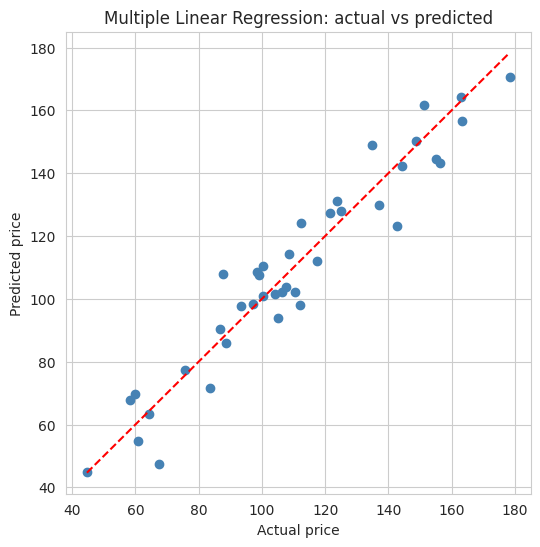

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_mlr, color="steelblue")
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color="red", linestyle="--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Multiple Linear Regression: actual vs predicted")
plt.show()

### Advantages
- Uses many features together, so it is more accurate than simple linear.
- Still fast and easy to interpret (each coefficient = effect of one feature).
- Works well when the real relation is roughly linear.

### Disadvantages
- Assumes a **linear** relation between features and target.
- **Multicollinearity**: if two features are highly correlated (like Area and Rooms), the coefficients become unstable.
- Sensitive to outliers.
- Needs the features to be numeric (encode text columns first, like in our encoder notebook).
- If you add too many useless features it can overfit.

---
# 3. Polynomial Regression

### Definition
Sometimes the data is **curved**, and a straight line can not fit it. Polynomial Regression fits a **curve** by adding powers of the feature (x squared, x cubed ...).

Equation (degree 2):

**y = b0 + b1*x + b2*x^2**

Funny part: it is still a *linear* model. We just create new columns (x, x^2, x^3 ...) with `PolynomialFeatures` and then run normal Linear Regression on them.

### Syntax
```python
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline

model = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
model.fit(X_train, y_train)
model.predict(X_test)
```

`degree` is the most important setting:
- degree 1 = straight line
- degree 2 = parabola (one bend)
- bigger degree = more wiggly curve

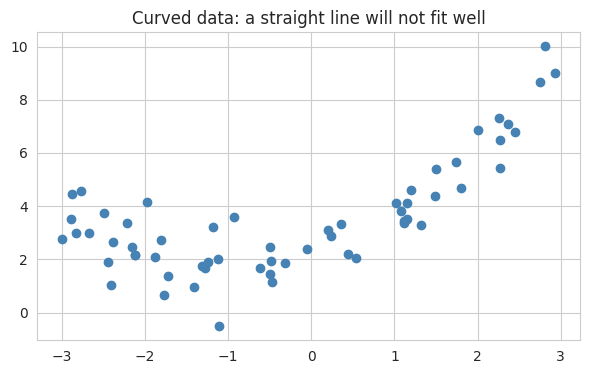

In [ ]:
# new data: curved relation (roughly y = 0.5x^2 + x + 2)
np.random.seed(1)
x = np.random.uniform(-3, 3, 60)
y_curve = 0.5 * x**2 + x + 2 + np.random.normal(0, 1, 60)

Xc = x.reshape(-1, 1)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, y_curve, test_size=0.3, random_state=42)

plt.figure(figsize=(7, 4))
plt.scatter(Xc, y_curve, color="steelblue")
plt.title("Curved data: a straight line will not fit well")
plt.show()

In [ ]:
# degree 1 = plain linear regression, degree 2 = polynomial
lin  = make_pipeline(PolynomialFeatures(degree=1), LinearRegression()).fit(Xc_train, yc_train)
poly = make_pipeline(PolynomialFeatures(degree=2), LinearRegression()).fit(Xc_train, yc_train)

print("Test scores:")
_ = reg_report(yc_test, lin.predict(Xc_test),  "Linear (degree 1)")
_ = reg_report(yc_test, poly.predict(Xc_test), "Polynomial (degree 2)")

Test scores:
Linear (degree 1)      MAE =    1.27 | RMSE =    1.49 | R2 =  0.197
Polynomial (degree 2)  MAE =    0.58 | RMSE =    0.71 | R2 =  0.820


The polynomial model is much better on curved data. What does PolynomialFeatures actually do to the data? Let's look:

In [ ]:
demo = pd.DataFrame({"x": [1, 2, 3]})
pf = PolynomialFeatures(degree=3, include_bias=False)

pd.DataFrame(pf.fit_transform(demo), columns=pf.get_feature_names_out(["x"]))

,x,x^2,x^3
0,1.0,1.0,1.0
1,2.0,4.0,8.0
2,3.0,9.0,27.0


It made x, x^2 and x^3 columns. Then linear regression finds one coefficient for each.

### Danger: Underfitting and Overfitting
This is the most important concept with polynomial regression. Let's try degree 1, 2 and 15.

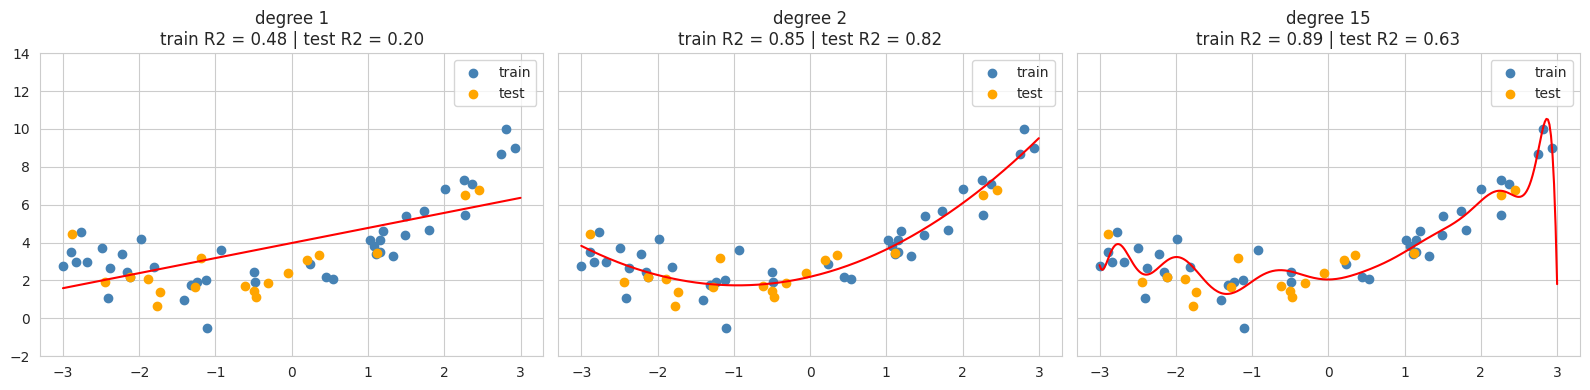

In [ ]:
x_line = np.linspace(-3, 3, 300).reshape(-1, 1)
degrees = [1, 2, 15]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for ax, d in zip(axes, degrees):
    m = make_pipeline(PolynomialFeatures(degree=d), StandardScaler(), LinearRegression()).fit(Xc_train, yc_train)
    train_r2 = r2_score(yc_train, m.predict(Xc_train))
    test_r2  = r2_score(yc_test,  m.predict(Xc_test))

    ax.scatter(Xc_train, yc_train, color="steelblue", label="train")
    ax.scatter(Xc_test,  yc_test,  color="orange", label="test")
    ax.plot(x_line, m.predict(x_line), color="red")
    ax.set_ylim(-2, 14)
    ax.set_title(f"degree {d}\ntrain R2 = {train_r2:.2f} | test R2 = {test_r2:.2f}")
    ax.legend()

plt.tight_layout()
plt.show()

| Degree | What happens | Train R2 | Test R2 | Name |
|---|---|---|---|---|
| 1 | Line can not follow the curve | Low | Low | **Underfitting** (model too simple) |
| 2 | Curve matches the real pattern | Good | Good | **Good fit** |
| 15 | Curve wiggles to touch every training point | Very high | Drops | **Overfitting** (model learned the noise) |

Overfitting = model remembers the training data but fails on new data. The way to catch it is to compare **train score vs test score**. If train is much higher than test, it is overfitting.

Let's find the best degree by checking test scores in a loop.

In [ ]:
rows = []
for d in range(1, 11):
    m = make_pipeline(PolynomialFeatures(degree=d), StandardScaler(), LinearRegression()).fit(Xc_train, yc_train)
    rows.append({"Degree": d,
                 "Train R2": r2_score(yc_train, m.predict(Xc_train)),
                 "Test R2":  r2_score(yc_test,  m.predict(Xc_test))})

deg_table = pd.DataFrame(rows).round(3)
deg_table

,Degree,Train R2,Test R2
0,1,0.478,0.197
1,2,0.849,0.820
2,3,0.854,0.796
3,4,0.854,0.783
4,5,0.856,0.782
5,6,0.856,0.783
6,7,0.857,0.787
7,8,0.857,0.788
8,9,0.859,0.768
9,10,0.870,0.750


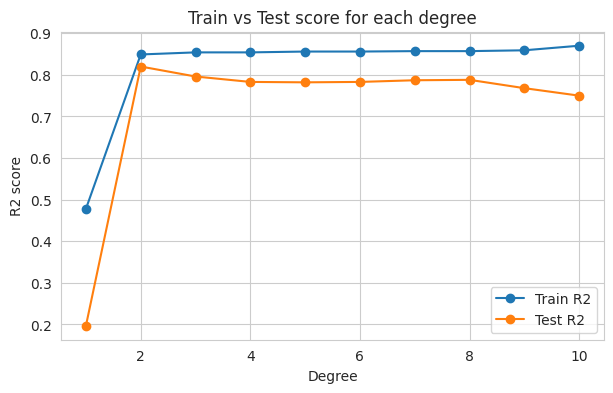

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(deg_table["Degree"], deg_table["Train R2"], marker="o", label="Train R2")
plt.plot(deg_table["Degree"], deg_table["Test R2"],  marker="o", label="Test R2")
plt.xlabel("Degree")
plt.ylabel("R2 score")
plt.title("Train vs Test score for each degree")
plt.legend()
plt.show()

Train score keeps going up with every degree, but the test score is best at degree 2 and then slowly goes down. So degree 2 is the right choice for this data.

### Advantages
- Can fit **curved (non-linear)** relations while using simple linear regression inside.
- Easy to build, only one extra step (`PolynomialFeatures`).
- Works well when we can see a curve in the scatter plot.

### Disadvantages
- **High degree = overfitting** very fast.
- Number of columns explodes with many features (3 features at degree 3 makes 19 columns).
- Very bad at predicting **outside the range** of the training data (the curve shoots up or down).
- Sensitive to outliers.
- Needs scaling for higher degrees (numbers like x^15 become huge).

---
# 4. Ridge Regression (L2 regularization)

### The problem they solve
Normal linear regression tries only to reduce the error. When there are many features (or a high-degree polynomial), the coefficients can become **very large** and the model overfits.

**Regularization** adds a **penalty for big coefficients** to the training goal. So the model has to keep coefficients small, and it becomes simpler and more stable.

### Definition of Ridge
Ridge adds the penalty = **alpha x (sum of squared coefficients)**. This is called **L2** penalty.
- It **shrinks** all coefficients towards zero.
- But it **never makes them exactly zero**. All features stay in the model.

### Syntax
```python
from sklearn.linear_model import Ridge

model = Ridge(alpha=1.0)      # alpha = strength of the penalty
model.fit(X_train_scaled, y_train)
```

`alpha`:
- alpha = 0 -> same as normal linear regression
- small alpha -> weak penalty
- large alpha -> strong penalty, coefficients become tiny (can underfit)

**Scaling is a must** for Ridge and Lasso, because the penalty treats all coefficients equally, and features with different units would be punished unfairly.

## 5. Lasso Regression (L1 regularization)

### Definition
Lasso adds the penalty = **alpha x (sum of absolute values of coefficients)**. This is called **L1** penalty.
- It also shrinks the coefficients.
- But it can push some of them to **exactly zero**, which means it **removes those features**. So Lasso does automatic **feature selection**.

### Syntax
```python
from sklearn.linear_model import Lasso

model = Lasso(alpha=1.0)
model.fit(X_train_scaled, y_train)
```

### Dataset for this part
Regularization helps most when there are **many features and very few rows**. So we create 30 features but only 50 rows, and **only 3 features really matter**. The other 27 are useless noise. Plain linear regression will try to use all 30 and overfit. Let's see.

In [ ]:
from sklearn.datasets import make_regression
from sklearn.linear_model import Ridge, Lasso

Xr, yr, true_coef = make_regression(n_samples=50, n_features=30, n_informative=3,
                                    noise=20, coef=True, random_state=42)

feat_names = [f"F{i+1}" for i in range(30)]
Xr = pd.DataFrame(Xr, columns=feat_names)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.3, random_state=42)

# scaling (fit on train only, then transform both)
sc = StandardScaler()
Xr_train_s = sc.fit_transform(Xr_train)
Xr_test_s  = sc.transform(Xr_test)

print("Features that are really useful (true coefficient != 0):")
print([f for f, c in zip(feat_names, true_coef) if c != 0])

Features that are really useful (true coefficient != 0):
['F5', 'F18', 'F29']


In [ ]:
lr_  = LinearRegression().fit(Xr_train_s, yr_train)
rid  = Ridge(alpha=10).fit(Xr_train_s, yr_train)
las  = Lasso(alpha=2).fit(Xr_train_s, yr_train)

score_rows = []
for name, m in [("Linear Regression", lr_), ("Ridge (alpha=10)", rid), ("Lasso (alpha=2)", las)]:
    score_rows.append({"Model": name,
                       "Train R2": r2_score(yr_train, m.predict(Xr_train_s)),
                       "Test R2":  r2_score(yr_test,  m.predict(Xr_test_s))})

pd.DataFrame(score_rows).set_index("Model").round(3)

,Train R2,Test R2
Model,,
Linear Regression,0.995,-0.151
Ridge (alpha=10),0.938,0.840
Lasso (alpha=2),0.981,0.923


Linear Regression has a near perfect **train** score but a very poor (even negative) **test** score. That is overfitting: with 30 features and only 35 training rows, it memorized the noise. Ridge and Lasso keep the train score a bit lower, but the test score is much better. (A negative R2 means the model is worse than just predicting the average.)

In [ ]:
# coefficient comparison table (scaled data, so compare the pattern, not exact true values)
coef_compare = pd.DataFrame({
    "Linear": lr_.coef_,
    "Ridge":  rid.coef_,
    "Lasso":  las.coef_
}, index=feat_names).round(2)

coef_compare["Truly useful?"] = ["Yes" if c != 0 else "No" for c in true_coef]
coef_compare

,Linear,Ridge,Lasso,Truly useful?
F1,-3.45,-0.45,-0.00,No
F2,2.42,3.60,0.00,No
F3,-15.00,-1.03,-2.15,No
F4,-6.82,-1.01,0.00,No
F5,109.97,68.76,96.75,Yes
F6,-13.16,0.26,0.00,No
F7,24.18,-8.06,-0.00,No
F8,-11.44,-3.12,-0.00,No
F9,21.22,-10.84,-0.00,No
F10,16.06,-4.67,-0.00,No


Look at the table (and compare it with the "Truly useful?" column):
- **Linear**: gives big, random weights to many useless features. That is how it overfits.
- **Ridge**: all weights are smaller and calmer, but none of them is exactly zero.
- **Lasso**: most of the useless features got **exactly 0.00** (removed), and the remaining weights are mostly on the useful features.

Let's see it in a picture.

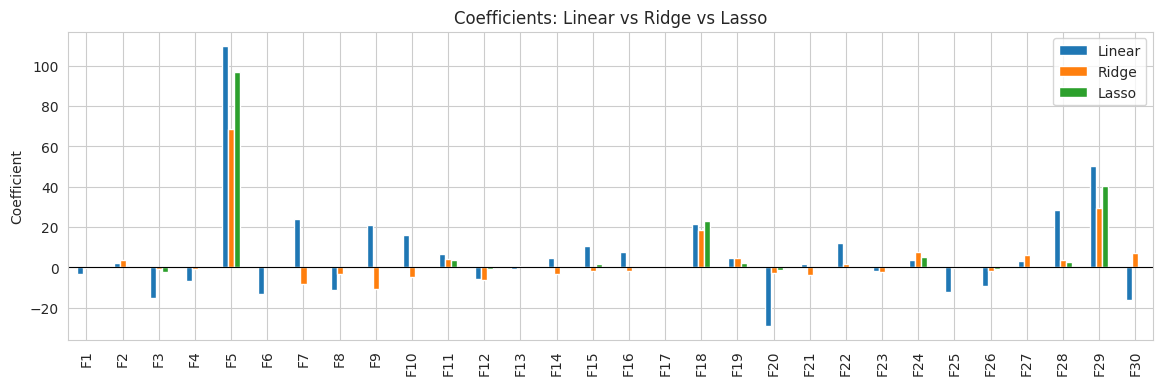

In [ ]:
coef_compare[["Linear", "Ridge", "Lasso"]].plot(kind="bar", figsize=(14, 4))
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Coefficients: Linear vs Ridge vs Lasso")
plt.ylabel("Coefficient")
plt.show()

### How alpha changes things
Let's try different alpha values for Lasso and count how many features it removes.

In [ ]:
rows = []
for a in [0.01, 0.1, 0.5, 1, 2, 5, 10, 30]:
    m = Lasso(alpha=a).fit(Xr_train_s, yr_train)
    rows.append({"alpha": a,
                 "Features kept": int((m.coef_ != 0).sum()),
                 "Features removed": int((m.coef_ == 0).sum()),
                 "Test R2": round(r2_score(yr_test, m.predict(Xr_test_s)), 3)})

pd.DataFrame(rows)

,alpha,Features kept,Features removed,Test R2
0,0.01,30,0,-0.001
1,0.10,28,2,0.593
2,0.50,23,7,0.824
3,1.00,18,12,0.887
4,2.00,14,16,0.923
5,5.00,5,25,0.914
6,10.00,4,26,0.909
7,30.00,3,27,0.787


As alpha goes up, more features are removed. With a very large alpha, Lasso removes even the useful features and the score drops (underfitting). So alpha must be chosen carefully.

### Choosing alpha automatically
Do not guess alpha. Use the built-in cross-validation versions:
```python
from sklearn.linear_model import RidgeCV, LassoCV

LassoCV(cv=5).fit(X_train_scaled, y_train).alpha_     # best alpha found
RidgeCV(alphas=[0.1, 1, 10, 100]).fit(X_train_scaled, y_train).alpha_
```

In [ ]:
from sklearn.linear_model import LassoCV, RidgeCV

lcv = LassoCV(cv=5, random_state=42).fit(Xr_train_s, yr_train)
rcv = RidgeCV(alphas=[0.1, 1, 10, 100]).fit(Xr_train_s, yr_train)

print("Best alpha for Lasso:", round(lcv.alpha_, 4))
print("Best alpha for Ridge:", rcv.alpha_)
print()
_ = reg_report(yr_test, lcv.predict(Xr_test_s), "LassoCV")
_ = reg_report(yr_test, rcv.predict(Xr_test_s), "RidgeCV")

Best alpha for Lasso: 4.6909
Best alpha for Ridge: 1.0

LassoCV                MAE =   15.73 | RMSE =   19.85 | R2 =  0.914
RidgeCV                MAE =   27.20 | RMSE =   30.87 | R2 =  0.791


### Ridge vs Lasso (difference table)

| Point | Ridge (L2) | Lasso (L1) |
|---|---|---|
| Penalty | alpha x sum of **squared** coefficients | alpha x sum of **absolute** coefficients |
| Coefficients | Shrink close to zero, **never exactly zero** | Can become **exactly zero** |
| Feature selection | No | **Yes**, automatic |
| Best when | Many features, all a bit useful, or features are correlated | Many features but only a few are useful |
| Correlated features | Shares weight between them | Picks one and drops the others (can be random) |
| Result model | Uses all features | Smaller, simpler model |
| Sklearn class | `Ridge`, `RidgeCV` | `Lasso`, `LassoCV` |

(There is also **ElasticNet**, which mixes both L1 and L2. Good option when you are not sure.)

### Advantages of Ridge and Lasso
- Reduce **overfitting** by keeping the coefficients small.
- Work well when there are many features.
- Ridge handles **multicollinearity** (correlated features) nicely.
- Lasso does **feature selection** for free, which gives a simpler model.

### Disadvantages
- Need **scaling** first.
- Need to tune **alpha** (use RidgeCV / LassoCV).
- Coefficients are biased (slightly wrong on purpose), so they are harder to interpret than plain linear regression.
- Lasso can behave randomly when features are highly correlated.
- Still linear models, so they can not capture curves unless you add polynomial features.

## Regression summary table

| Algorithm | Features | Curved data | Overfitting control | Feature selection | Use when |
|---|---|---|---|---|---|
| Simple Linear | 1 | No | No | No | One feature, straight-line relation |
| Multiple Linear | Many | No | No | No | Many features, linear relation |
| Polynomial | 1 or many | **Yes** | No (careful with degree) | No | Curved relation |
| Ridge | Many | No | **Yes (L2)** | No | Many / correlated features |
| Lasso | Many | No | **Yes (L1)** | **Yes** | Many features, few useful |

---
# PART B: CLASSIFICATION
Classification = predicting a **class / category**.

## Dataset: Breast Cancer (built into scikit-learn)
- 569 patients, 30 numeric features (size, texture, smoothness of the tumour cells ...)
- Target: `0` = malignant (cancer), `1` = benign (not cancer)

No download needed, it comes with sklearn.

In [ ]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)
Xc_all = cancer.data
yc_all = cancer.target

print("Shape:", Xc_all.shape)
print("Classes:", dict(zip([0, 1], cancer.target_names.tolist())))
print()
print(yc_all.value_counts())

Shape: (569, 30)
Classes: {0: 'malignant', 1: 'benign'}

target
1    357
0    212
Name: count, dtype: int64


In [ ]:
Xc_all.iloc[:, :6].head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,17.99,10.38,122.80,1001.0,0.11840,0.27760
1,20.57,17.77,132.90,1326.0,0.08474,0.07864
2,19.69,21.25,130.00,1203.0,0.10960,0.15990
3,11.42,20.38,77.58,386.1,0.14250,0.28390
4,20.29,14.34,135.10,1297.0,0.10030,0.13280


## Train/test split and scaling

Two things to take care of:
1. `stratify=y` keeps the same ratio of classes in train and test.
2. **Scale after splitting.** We `fit` the scaler on the train data only, and then `transform` both. If we fit on the full data, test information leaks into training (called **data leakage**).

Which models need scaling?
- **Need it**: KNN, Logistic Regression, SVC (they depend on distance or size of numbers)
- **Do not need it**: Decision Tree, Random Forest (they only compare values by splitting)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    Xc_all, yc_all, test_size=0.2, random_state=42, stratify=yc_all)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)     # learn mean/std from train only
X_test_s  = scaler.transform(X_test)          # just apply it to test

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (455, 30) | Test: (114, 30)


## Metrics for classification

First the **confusion matrix**. For a binary problem it has 4 boxes:

| | Predicted: Positive | Predicted: Negative |
|---|---|---|
| **Actual: Positive** | TP (True Positive) | FN (False Negative) |
| **Actual: Negative** | FP (False Positive) | TN (True Negative) |

| Metric | Formula | Meaning |
|---|---|---|
| **Accuracy** | (TP + TN) / total | How many predictions are right overall |
| **Precision** | TP / (TP + FP) | Of all predicted positive, how many are really positive |
| **Recall** | TP / (TP + FN) | Of all real positives, how many did we catch |
| **F1 score** | 2 x (P x R) / (P + R) | Balance between precision and recall |

Accuracy alone can be misleading. In medical problems, **recall** is often very important, because missing a real patient (FN) is dangerous.

Syntax:
```python
accuracy_score(y_test, y_pred)
confusion_matrix(y_test, y_pred)
classification_report(y_test, y_pred)     # precision, recall, f1 for each class
```

In [ ]:
# helper: train, predict, print scores, store result
results = []

def clf_report(name, y_true, y_pred):
    row = {
        "Model": name,
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall":    recall_score(y_true, y_pred),
        "F1":        f1_score(y_true, y_pred),
    }
    results.append(row)
    print(f"{name:<20} Accuracy = {row['Accuracy']:.3f} | Precision = {row['Precision']:.3f} | "
          f"Recall = {row['Recall']:.3f} | F1 = {row['F1']:.3f}")

---
# 6. KNN Classification (K-Nearest Neighbors)

### Definition
KNN is the simplest idea in machine learning: **"tell me who your neighbors are, and I will tell you who you are."**

To predict a new point:
1. Find the **K nearest** points in the training data (by distance).
2. Let them **vote**. The class with the most votes wins.

There is **no real training**. KNN just stores the data (called a *lazy learner*) and does all the work at prediction time.

### Syntax
```python
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train_scaled, y_train)
model.predict(X_test_scaled)
```

Important parameters:
| Parameter | Meaning |
|---|---|
| `n_neighbors` (K) | How many neighbors vote. Default 5 |
| `weights="distance"` | Closer neighbors get more vote power |
| `metric` | Distance type (default Euclidean) |

**Scaling is a must**, because distance is calculated with the feature values. A feature with big numbers (like area in the thousands) would dominate a feature with small numbers.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)

clf_report("KNN (k=5)", y_test, knn.predict(X_test_s))

KNN (k=5)            Accuracy = 0.956 | Precision = 0.959 | Recall = 0.972 | F1 = 0.966


### Choosing the best K
- **Small K** (like 1): follows noise, overfits.
- **Large K**: too smooth, underfits.

We try K from 1 to 25 and compare train vs test accuracy.

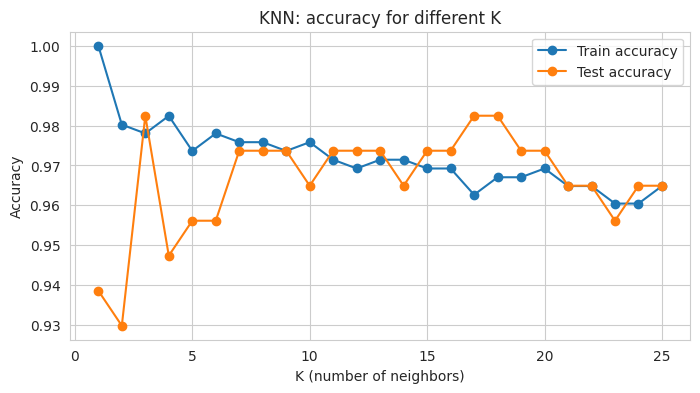

Best K on test data: 3


In [ ]:
k_values = range(1, 26)
train_acc, test_acc = [], []

for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    train_acc.append(m.score(X_train_s, y_train))
    test_acc.append(m.score(X_test_s, y_test))

plt.figure(figsize=(8, 4))
plt.plot(k_values, train_acc, marker="o", label="Train accuracy")
plt.plot(k_values, test_acc,  marker="o", label="Test accuracy")
plt.xlabel("K (number of neighbors)")
plt.ylabel("Accuracy")
plt.title("KNN: accuracy for different K")
plt.legend()
plt.show()

best_k = list(k_values)[int(np.argmax(test_acc))]
print("Best K on test data:", best_k)

In [ ]:
# what if we forget to scale? (this is why scaling matters)
knn_noscale = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print("KNN without scaling:", round(knn_noscale.score(X_test, y_test), 3))
print("KNN with scaling   :", round(knn.score(X_test_s, y_test), 3))

KNN without scaling: 0.912
KNN with scaling   : 0.956


### Advantages
- Very simple, easy to understand.
- **No training time** and no assumption about the data shape.
- Works for both classification and regression (`KNeighborsRegressor`).
- Naturally handles multi-class problems.

### Disadvantages
- **Slow at prediction** with big data (it compares with all stored points every time).
- Needs **scaling**.
- Struggles with many features (curse of dimensionality) and irrelevant features.
- Sensitive to outliers and noisy data (for small K).
- Needs a good K value.
- Uses a lot of memory (stores the whole training set).

---
# 7. Logistic Regression

### Definition
Despite the name "regression", it is a **classification** algorithm.

It works like linear regression first (a weighted sum of the features), and then passes the result through the **sigmoid function**, which squeezes any number into a **probability between 0 and 1**.

**probability = 1 / (1 + e^(-z))**, where z = b0 + b1*x1 + b2*x2 + ...

Then a **threshold** (normally 0.5) decides the class:
- probability >= 0.5 -> class 1
- probability < 0.5 -> class 0

### Syntax
```python
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

model.predict(X_test_scaled)          # class (0 or 1)
model.predict_proba(X_test_scaled)    # probability of each class
```

Important parameters:
| Parameter | Meaning |
|---|---|
| `C` | Inverse of regularization strength. **Small C = strong penalty.** Default 1.0 |
| `penalty` | `"l2"` (default, like Ridge) or `"l1"` (like Lasso, needs `solver="liblinear"`) |
| `max_iter` | Maximum training steps. Increase it if you get a "did not converge" warning |

In [ ]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_s, y_train)

y_pred_lr = logreg.predict(X_test_s)
clf_report("Logistic Regression", y_test, y_pred_lr)

Logistic Regression  Accuracy = 0.982 | Precision = 0.986 | Recall = 0.986 | F1 = 0.986


In [ ]:
# probabilities: first 5 test patients
proba = logreg.predict_proba(X_test_s)[:5]

pd.DataFrame({
    "P(malignant=0)": proba[:, 0].round(3),
    "P(benign=1)":    proba[:, 1].round(3),
    "Predicted":      logreg.predict(X_test_s)[:5],
    "Actual":         y_test.values[:5]
})

,P(malignant=0),P(benign=1),Predicted,Actual
0,1.000,0.000,0,0
1,0.000,1.000,1,1
2,0.994,0.006,0,0
3,0.466,0.534,1,1
4,1.000,0.000,0,0


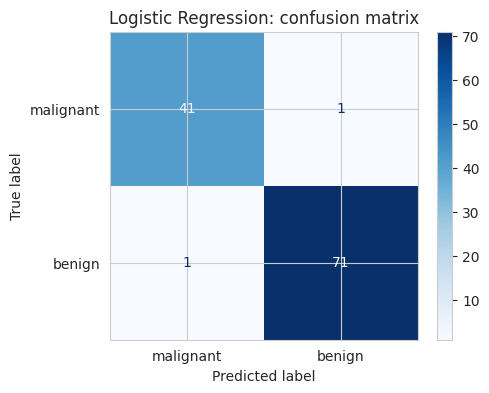

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [ ]:
# confusion matrix + full report
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, display_labels=cancer.target_names, cmap="Blues", ax=ax)
plt.title("Logistic Regression: confusion matrix")
plt.show()

print(classification_report(y_test, y_pred_lr, target_names=cancer.target_names))

Read the confusion matrix like this: the diagonal boxes (top-left and bottom-right) are the **correct** predictions. The other two boxes are the mistakes. For cancer prediction, the most dangerous mistake is predicting "benign" for a patient who really has "malignant".

### Advantages
- Simple, fast and works very well as a **baseline**.
- Gives **probabilities**, not only the class (useful in real life, like "80% chance of default").
- Coefficients can be interpreted (which feature pushes towards which class).
- Less prone to overfitting, especially with regularization (`C`).

### Disadvantages
- Assumes a **linear** boundary between classes. It can not catch very complex patterns.
- Needs **scaling** for good results.
- Affected by multicollinearity and outliers.
- Can underfit on complex data.

---
# 8. Decision Tree

### Definition
A Decision Tree asks a series of **yes/no questions** about the features, like a flowchart, until it reaches a final answer.

Example: "Is mean radius <= 15? -> Yes -> Is mean texture <= 20? -> ... -> Benign".

How does it choose the questions? At each step it picks the feature and split value that **separates the classes best**, measured by **Gini impurity** (default) or **entropy**. (Pure box = all samples of one class = impurity 0.)

### Syntax
```python
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)          # no scaling needed
```

Important parameters (these control overfitting):
| Parameter | Meaning |
|---|---|
| `max_depth` | Maximum number of question levels. **Most important one** |
| `min_samples_split` | Minimum samples needed to split a node |
| `min_samples_leaf` | Minimum samples in the final box |
| `criterion` | `"gini"` or `"entropy"` |

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_train, y_train)                    # notice: unscaled data is fine

clf_report("Decision Tree", y_test, dt.predict(X_test))

Decision Tree        Accuracy = 0.939 | Precision = 0.945 | Recall = 0.958 | F1 = 0.952


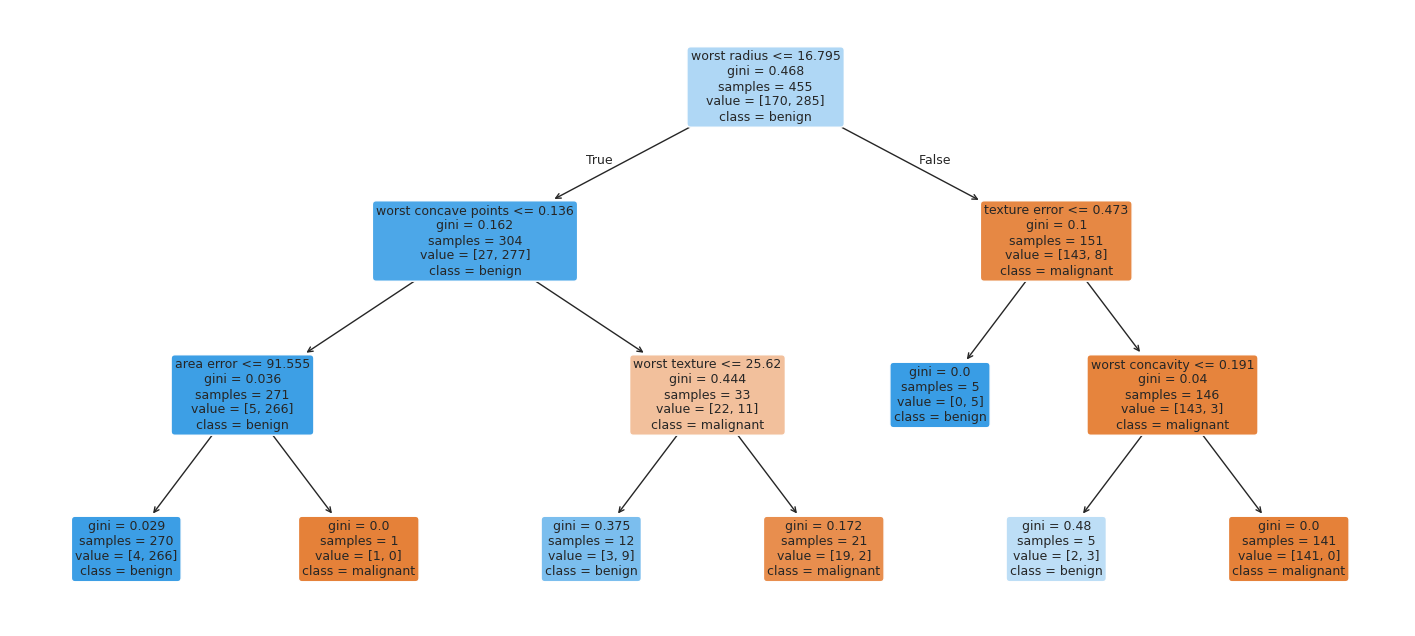

In [ ]:
# draw the tree: this is why decision trees are easy to explain
plt.figure(figsize=(18, 8))
plot_tree(dt, feature_names=Xc_all.columns, class_names=cancer.target_names, filled=True, rounded=True, fontsize=9)
plt.show()

How to read the tree: start from the top box (root). Each box shows the question, the `gini` impurity, how many samples reached it, and the majority class. Follow YES to the left, NO to the right, until you reach a last box (leaf) that gives the answer.

### Overfitting in trees
A tree with no depth limit keeps splitting until every training sample is perfectly classified. That is memorizing, not learning.

In [ ]:
rows = []
for d in [1, 2, 3, 4, 5, 8, None]:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    rows.append({"max_depth": "None (no limit)" if d is None else d,
                 "Train accuracy": round(m.score(X_train, y_train), 3),
                 "Test accuracy":  round(m.score(X_test, y_test), 3)})

pd.DataFrame(rows)

,max_depth,Train accuracy,Test accuracy
0,1,0.923,0.921
1,2,0.958,0.895
2,3,0.976,0.939
3,4,0.987,0.939
4,5,0.993,0.921
5,8,1.000,0.912
6,None (no limit),1.000,0.912


With no limit the train accuracy becomes 1.000 (perfect) but the test accuracy is lower, so it overfits. A shallow tree has similar train and test scores, which is healthier.

### Which features did the tree use most?

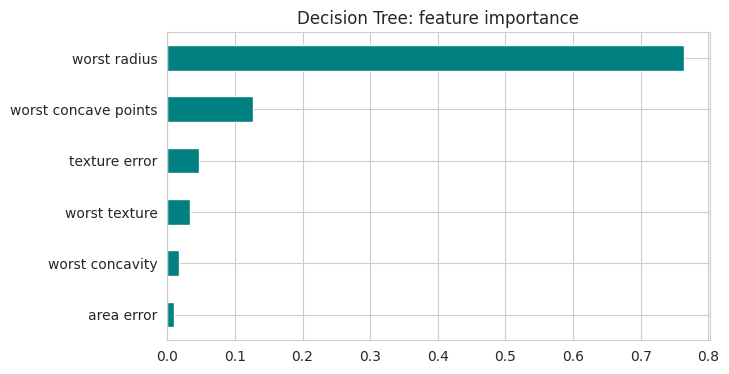

In [ ]:
imp = pd.Series(dt.feature_importances_, index=Xc_all.columns).sort_values(ascending=False)
imp[imp > 0].plot(kind="barh", figsize=(7, 4), color="teal")
plt.gca().invert_yaxis()
plt.title("Decision Tree: feature importance")
plt.show()

### Advantages
- Very easy to **understand and explain** (you can draw it).
- **No scaling** needed.
- Handles numeric and categorical data, and non-linear patterns.
- Gives feature importance.
- Not much affected by outliers.

### Disadvantages
- **Overfits very easily** if depth is not limited.
- **Unstable**: a small change in data can create a totally different tree.
- Single trees are usually less accurate than ensemble methods (like Random Forest).
- Creates boxy (step-like) decision boundaries.

---
# 9. Random Forest

### Definition
One tree is unstable and overfits. So what if we build **many trees** and let them vote? That is a Random Forest. It is an **ensemble** method (a team of models).

How it creates different trees:
1. **Bagging**: every tree trains on a different random sample of the rows (with repetition).
2. **Random features**: at every split a tree only looks at a random subset of the features.

Each tree makes its own prediction, and the **majority vote** is the final answer. Mistakes of individual trees cancel out, so the forest is more accurate and stable.

### Syntax
```python
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)           # no scaling needed
```

Important parameters:
| Parameter | Meaning |
|---|---|
| `n_estimators` | Number of trees. More = better but slower. Default 100 |
| `max_depth` | Depth limit for each tree |
| `max_features` | How many features each split can see |
| `min_samples_leaf` | Minimum samples in a leaf |
| `n_jobs=-1` | Use all CPU cores to train faster |

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

clf_report("Random Forest", y_test, rf.predict(X_test))

Random Forest        Accuracy = 0.956 | Precision = 0.959 | Recall = 0.972 | F1 = 0.966


In [ ]:
# single tree vs forest: train and test accuracy
full_tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

print(f"Single deep tree -> train: {full_tree.score(X_train, y_train):.3f} | test: {full_tree.score(X_test, y_test):.3f}")
print(f"Random Forest    -> train: {rf.score(X_train, y_train):.3f} | test: {rf.score(X_test, y_test):.3f}")

Single deep tree -> train: 1.000 | test: 0.912
Random Forest    -> train: 1.000 | test: 0.956


In [ ]:
# how many trees do we need?
rows = []
for n_trees in [1, 5, 10, 25, 50, 100, 200]:
    m = RandomForestClassifier(n_estimators=n_trees, random_state=42, n_jobs=-1).fit(X_train, y_train)
    rows.append({"n_estimators": n_trees, "Test accuracy": round(m.score(X_test, y_test), 3)})

pd.DataFrame(rows)

,n_estimators,Test accuracy
0,1,0.947
1,5,0.939
2,10,0.939
3,25,0.956
4,50,0.956
5,100,0.956
6,200,0.956


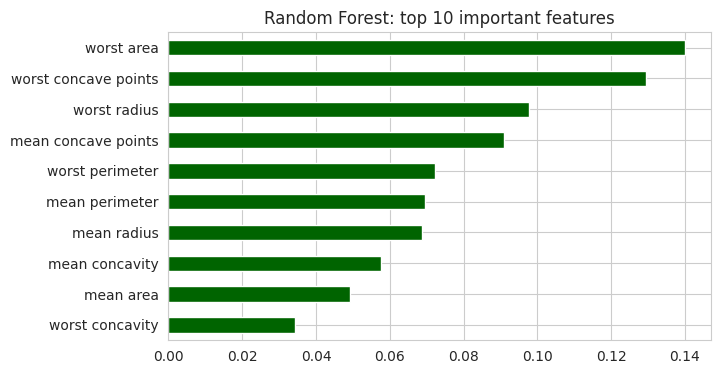

In [ ]:
# feature importance: top 10
imp_rf = pd.Series(rf.feature_importances_, index=Xc_all.columns).sort_values(ascending=False).head(10)

imp_rf.plot(kind="barh", figsize=(7, 4), color="darkgreen")
plt.gca().invert_yaxis()
plt.title("Random Forest: top 10 important features")
plt.show()

### Advantages
- **High accuracy**, usually much better than a single tree.
- Much **less overfitting** than a decision tree.
- **No scaling** needed.
- Handles many features, non-linear data, and missing/outlier issues quite well.
- Gives feature importance.
- Works well with default settings, so it is a great first model for tabular data.

### Disadvantages
- **Slower** and uses more memory (100 trees instead of 1).
- **Hard to interpret**: you can not draw 100 trees and explain them (black box).
- Bigger model files.
- Not good at extrapolation (predicting outside the range of training data).
- Can still overfit on very noisy data if trees are too deep.

---
# 10. SVC (Support Vector Classifier)

### Definition
SVC (part of **SVM**, Support Vector Machine) finds the **best dividing line (hyperplane)** between the classes, which has the **maximum margin** (the widest empty gap) between the two classes.

The points closest to the line are called **support vectors**. They are the only points that decide the line.

What if the classes can not be separated by a straight line? SVC uses the **kernel trick**: it lifts the data into a higher dimension, where a separating boundary becomes possible.

### Syntax
```python
from sklearn.svm import SVC

model = SVC(kernel="rbf", C=1.0, gamma="scale")
model.fit(X_train_scaled, y_train)
```

Important parameters:
| Parameter | Meaning |
|---|---|
| `kernel` | `"linear"`, `"rbf"` (default, curved boundary), `"poly"`, `"sigmoid"` |
| `C` | Penalty for wrong points. **Large C** = strict, tries to classify every point (can overfit). **Small C** = softer margin (can underfit) |
| `gamma` | For rbf: how far one point's influence reaches. **Large gamma** = very wiggly boundary (overfit) |
| `probability=True` | Needed if you want `predict_proba` (slower) |

**Scaling is a must** for SVC.

In [ ]:
from sklearn.svm import SVC

svc = SVC(kernel="rbf", C=1.0, gamma="scale")
svc.fit(X_train_s, y_train)

clf_report("SVC (rbf)", y_test, svc.predict(X_test_s))

SVC (rbf)            Accuracy = 0.982 | Precision = 0.986 | Recall = 0.986 | F1 = 0.986


In [ ]:
# different kernels
rows = []
for k in ["linear", "rbf", "poly", "sigmoid"]:
    m = SVC(kernel=k).fit(X_train_s, y_train)
    rows.append({"Kernel": k,
                 "Train accuracy": round(m.score(X_train_s, y_train), 3),
                 "Test accuracy":  round(m.score(X_test_s, y_test), 3)})

pd.DataFrame(rows)

,Kernel,Train accuracy,Test accuracy
0,linear,0.991,0.974
1,rbf,0.982,0.982
2,poly,0.916,0.912
3,sigmoid,0.956,0.930


In [ ]:
# effect of C
rows = []
for c in [0.01, 0.1, 1, 10, 100]:
    m = SVC(kernel="rbf", C=c).fit(X_train_s, y_train)
    rows.append({"C": c,
                 "Train accuracy": round(m.score(X_train_s, y_train), 3),
                 "Test accuracy":  round(m.score(X_test_s, y_test), 3)})

pd.DataFrame(rows)

,C,Train accuracy,Test accuracy
0,0.01,0.626,0.632
1,0.10,0.958,0.947
2,1.00,0.982,0.982
3,10.00,0.993,0.974
4,100.00,1.000,0.947


In [ ]:
# scaling matters a lot for SVC
svc_noscale = SVC(kernel="rbf").fit(X_train, y_train)
print("SVC without scaling:", round(svc_noscale.score(X_test, y_test), 3))
print("SVC with scaling   :", round(svc.score(X_test_s, y_test), 3))

SVC without scaling: 0.93
SVC with scaling   : 0.982


### Advantages
- Very effective in **high-dimensional** data (many features).
- Works well with a clear margin between classes.
- Can learn **non-linear** boundaries with kernels.
- Memory efficient, because only the support vectors matter.

### Disadvantages
- **Slow** on large datasets (training time grows quickly with rows).
- **Needs scaling** and tuning of `C` and `gamma`.
- Does not give probabilities directly (`probability=True` makes it slower).
- Hard to interpret, especially with non-linear kernels.
- Struggles when the data is very noisy and classes overlap a lot.

---
# 11. Final comparison of all classifiers

We already stored the test scores. Let's put all of them in one table.

In [ ]:
compare_df = pd.DataFrame(results).set_index("Model").round(3)
compare_df.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.982,0.986,0.986,0.986
SVC (rbf),0.982,0.986,0.986,0.986
KNN (k=5),0.956,0.959,0.972,0.966
Random Forest,0.956,0.959,0.972,0.966
Decision Tree,0.939,0.945,0.958,0.952


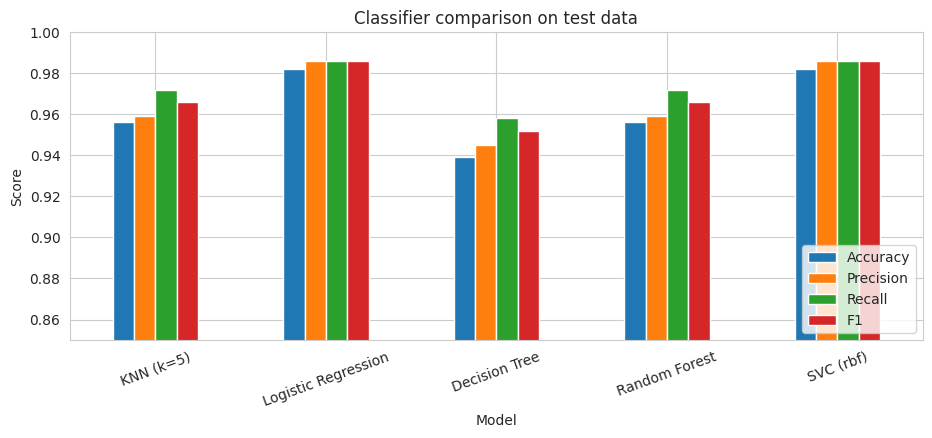

In [ ]:
compare_df[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(11, 4))
plt.ylim(0.85, 1.0)
plt.title("Classifier comparison on test data")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.show()

Caution: the test set here has only 114 patients. So the differences of 1 or 2 patients can change the ranking. A more reliable comparison is **cross-validation**: the data is split in 5 parts, the model is trained and tested 5 times, and we take the average.

For models that need scaling, we put the scaler inside a **pipeline**, so scaling happens correctly inside every fold (no data leakage).

In [ ]:
models = {
    "KNN":                 make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree":       DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
    "SVC":                 make_pipeline(StandardScaler(), SVC()),
}

cv_rows = []
for name, m in models.items():
    scores = cross_val_score(m, Xc_all, yc_all, cv=5, scoring="accuracy")
    cv_rows.append({"Model": name, "Mean accuracy": scores.mean(), "Std": scores.std()})

cv_df = pd.DataFrame(cv_rows).set_index("Model").round(3).sort_values("Mean accuracy", ascending=False)
cv_df

,Mean accuracy,Std
Model,,
Logistic Regression,0.981,0.007
SVC,0.974,0.015
KNN,0.965,0.010
Random Forest,0.956,0.023
Decision Tree,0.919,0.025


The mean accuracy over 5 folds is a more trustworthy number than a single test split. The `Std` column shows how much the score moves between folds (lower = more stable).

### Difference table: all five classifiers

| Point | KNN | Logistic Regression | Decision Tree | Random Forest | SVC |
|---|---|---|---|---|---|
| **Idea** | Vote of nearest neighbors | Sigmoid on a weighted sum | Flowchart of yes/no questions | Many trees voting | Widest margin between classes |
| **Boundary** | Flexible | Straight (linear) | Boxy (steps) | Boxy but smooth | Linear or curved (kernel) |
| **Needs scaling** | Yes | Yes | No | No | Yes |
| **Training speed** | Instant (no training) | Fast | Fast | Medium | Slow on big data |
| **Prediction speed** | Slow | Very fast | Very fast | Medium | Medium |
| **Interpretability** | Easy idea, hard to explain results | Good (coefficients) | **Best** (draw the tree) | Poor (black box) | Poor |
| **Overfitting risk** | High for small K | Low | **High** | Low | Medium (depends on C, gamma) |
| **Gives probability** | Yes | **Yes (natural)** | Yes | Yes | Only with `probability=True` |
| **Key settings** | `n_neighbors` | `C` | `max_depth` | `n_estimators`, `max_depth` | `kernel`, `C`, `gamma` |
| **Handles non-linear data** | Yes | No | Yes | Yes | Yes (rbf kernel) |
| **Best for** | Small data, quick baseline | Baseline, need probabilities | Need explanation | Best all-rounder for tables | Many features, medium data |

### Same syntax for every model
All models follow the same pattern. Only the first line changes:
```python
model = KNeighborsClassifier()        # or LogisticRegression(), DecisionTreeClassifier(),
                                      # RandomForestClassifier(), SVC()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
model.score(X_test, y_test)           # accuracy
```

---
# 12. Which algorithm should I use?

**For regression (predicting numbers):**
1. One feature, straight line -> Simple Linear Regression
2. Many features, linear -> Multiple Linear Regression
3. Curved relation -> Polynomial Regression (watch the degree)
4. Many features, overfitting -> Ridge
5. Many features, want to remove useless ones -> Lasso

**For classification (predicting classes):**
1. Start with **Logistic Regression** as a baseline (fast, simple).
2. Need to explain the decision to someone -> **Decision Tree**.
3. Want the best accuracy without much tuning -> **Random Forest**.
4. Many features and medium-size data -> **SVC**.
5. Very small dataset and want something quick -> **KNN**.

**Golden rule:** there is no single best algorithm. Try 3 or 4 models, compare them with cross-validation, then pick one.

---
# Common mistakes to avoid
- Fitting the scaler on the **full data** before the split (data leakage). Fit on train only.
- Forgetting to scale for KNN, SVC, Logistic Regression, Ridge and Lasso.
- Judging a model only by **train score**. Always check the test score or cross-validation.
- Using **accuracy only** on imbalanced data (if 95% patients are healthy, a model that always says "healthy" gets 95%). Check precision, recall and F1.
- Using too high a polynomial degree or an unlimited tree depth (overfitting).
- Using a single small test set to rank models that are only 1% apart.
- Forgetting `random_state`, so results change on every run.

---
# Summary

| Algorithm | Type | One line to remember |
|---|---|---|
| Simple Linear | Regression | Best straight line with one feature |
| Multiple Linear | Regression | Same, but with many features |
| Polynomial | Regression | Add powers of x to fit a curve (watch the degree) |
| Ridge | Regression | Linear + L2 penalty, shrinks coefficients |
| Lasso | Regression | Linear + L1 penalty, removes useless features |
| KNN | Classification | Vote of the K nearest neighbors |
| Logistic Regression | Classification | Sigmoid probability, linear boundary |
| Decision Tree | Classification | Flowchart of questions, easy to explain, overfits |
| Random Forest | Classification | Many trees voting, strong and stable |
| SVC | Classification | Widest margin line, kernel trick for curves |

### Practice tasks
1. Load the **Iris** dataset (`load_iris`) and run all five classifiers. Which one wins?
2. Take the **California Housing** dataset (`fetch_california_housing`) and compare Linear, Ridge and Lasso.
3. Try `RandomForestRegressor` and `KNeighborsRegressor` on the house price data. Most classification algorithms here also have a regression version.